# 08 — Pilot Report

In [1]:
# Cell 1 — setup
import sys, pathlib
sys.path.append(str(pathlib.Path.cwd().parent / "src"))
from scorelab import config, data
con = data.connect()            # read-only DuckDB connection to data/lc.duckdb

In [2]:
# Cell 2 — sanity check
print(con.sql("SHOW TABLES"))
print(con.sql("SELECT COUNT(*) AS n, MIN(issue_d), MAX(issue_d) FROM accepted"))

┌─────────────────┐
│      name       │
│     varchar     │
├─────────────────┤
│ accepted        │
│ rejected        │
│ v_accepted_asof │
│ v_split         │
│ v_target        │
└─────────────────┘

┌─────────┬──────────────┬──────────────┐
│    n    │ min(issue_d) │ max(issue_d) │
│  int64  │     date     │     date     │
├─────────┼──────────────┼──────────────┤
│ 2260668 │ 2007-06-01   │ 2018-12-01   │
└─────────┴──────────────┴──────────────┘



In [3]:
# Cell 3 — common imports and settings for this notebook
import json, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)
from scorelab import target, attributes as A, binning as B, scorecard as S, validation as V, fairness as F
from scorelab import challengers as C, reject_inference as R, monitoring as M, report as REP
MODELS = config.MODELS_DIR; MODELS.mkdir(exist_ok=True)
SAMPLE_FRAC = None     # None = full data (recommended for the fitting notebooks); e.g. 0.10 for a quick pass
cols = [r[0] for r in con.execute("DESCRIBE v_target").fetchall()]
assert "label" in cols, "v_target is the old stub: close this kernel and run `python scripts/refresh_views.py`"
def load_frame(splits=("train", "validate", "oot"), **kw):
    """Observable, non-excluded loans with attributes built; indeterminates dropped unless asked."""
    f = target.modeling_frame(con, splits=splits, sample_frac=SAMPLE_FRAC, **kw)
    return A.build_attributes(f)
MEANINGS = {a.name: a.meaning for a in A.REGISTRY}
DIRECTIONS = {a.name: a.direction for a in A.REGISTRY}

## What this notebook settles

The lender-pilot report: the champion against the incumbent (FICO midpoint) on the out-of-time vintage, with every exhibit a lender reads — discrimination with intervals, gains tables, the swap set at the lender's approval rate, calibration, segments, stability, and fair-lending tests on a proxy. The numbers come from `scorelab.report.pilot_exhibits`; the interpretation under each exhibit is yours.

Decisions: **Q — approval rate and segments**, **R — the fairness proxy**, **S — the interpretations and caveats**.

In [4]:
frame = load_frame(include_indeterminate=True)
card, specs = S.load_card(MODELS / "champion")
for d in (frame,):
    sc = S.score(d, card, specs); d["score"] = sc["score"].values; d["eta"] = sc["eta"].values; d["p_bad"] = sc["p_bad"].values
tr = frame[(frame.split == "train") & frame.bad.notna()]; oot = frame[(frame.split == "oot") & frame.bad.notna()]
indet = frame[(frame.split == "oot") & frame.bad.isna()]
print("oot", oot.shape, "indeterminates in oot", len(indet))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

oot (419611, 87) indeterminates in oot 6007


### Decision Q — Approval rate and segments

The swap set is read at one operating point; use the lender's real approval rate (config default 70%). Segments: term, purpose, file depth (`total_acc` bands), vintage quarter.

**Your reasoning:**

**DRAFT** (Claude, 2026-11-01, from this notebook's full-data outputs; for review). The notebook ran with the defaults in the code cells; this draft says whether to keep them.

**Keep 70% as the approval rate and the four segments** (term, file depth, purpose, vintage quarter).

**Both scores approve exactly 293,728 loans at 70%.** FICO moves in 5-point steps, so loans tie at its cutoff. The swap set now breaks ties at random (seeded), so the two books have the same size. Before this fix, FICO approved 72.9%.

**Population.** The 70% cutoff is applied to loans Lending Club already approved, so the swap set shows reordering within the booked 2016 population, not outcomes for declined applicants. The report says so at the top of the swap-set section and in the GBM appendix.

**At 70%, card against FICO:**
- 66,965 swap-ins with a bad rate of 11.99%, against 66,965 swap-outs at 17.48%.
- The approved book's bad rate falls from 10.50% to 9.25%, which is 125 bads avoided per 10,000 approvals.

**The benefit is largest at 50% (157 per 10,000) and smallest at 90% (60).** So the lender's real approval rate matters, and the swap curve should be shown beside the 70% point.

**The card beats FICO in every segment with enough loans:**
- 36-month 0.2847 against 0.1834; 60-month 0.3029 against 0.1856.
- Thin files (10 or fewer trades) 0.2101 against 0.1128.

**Two purposes are too small to read:** `renewable_energy` (297 loans) and `wedding` (1 loan). Fold purposes under 1,000 loans into "other" before the report is final.

**Gini falls through 2016 for both scores:** the card goes from 0.3134 in 2016Q1 to 0.2575 in 2016Q4, and FICO from 0.2048 to 0.1632.

### Decision R — Fairness proxy

Lending Club carries no protected-class fields. Choose and document a proxy (a geography-based grouping from `addr_state` is the usual stand-in in public data), or state that fairness testing is out of scope for this data and keep the code path demonstrated.

**Your reasoning:**

**DRAFT** (Claude, 2026-11-01, from this notebook's full-data outputs; for review). The notebook ran with the defaults in the code cells; this draft says whether to keep them.

**State that fair-lending testing is out of scope for this data. Keep the code path demonstrated with the geographic placeholder, clearly labelled as a placeholder.**

The proxy splits loans into Southern states and the rest, with 140,381 and 279,230 loans.

| Measure | Southern states | Other states |
|---|---:|---:|
| Approval rate at the cutoff | 69.15% | 70.44% |
| Gini | 0.2806 | 0.2853 |
| Calibration slope | 1.010 | 1.012 |

- **Adverse impact ratio:** 0.9817, far above four-fifths.
- **Standardized mean difference of scores:** −0.041.

**This shows the code works, not that the card is fair.** Region is not a protected class, and Lending Club records no protected-class data. A real test needs BISG-style proxies or lender data, which this project does not have.

In [5]:
APPROVAL_RATE = config.APPROVAL_RATE_FOR_SWAP
FICO_CAVEAT = ("Lending Club used FICO in its approval, so FICO's range is truncated in this booked population (no loan "
               "below a FICO midpoint of 662 in these vintages). Its Gini here understates what FICO does on a full applicant "
               "population, and every comparison with FICO in this report measures lift over a truncated incumbent.")
print("FICO caveat:", FICO_CAVEAT)
oot["file_depth"] = pd.cut(oot["total_acc"], [-1, 10, 20, 35, 1000], labels=["thin (<=10)", "11-20", "21-35", "thick (>35)"]).astype(str)
SEGMENTS = ("term_months", "file_depth", "purpose", "vintage_quarter")
SOUTH = {"TX","FL","GA","NC","SC","AL","MS","LA","TN","KY","AR","OK","VA","WV"}
oot["proxy_group"] = np.where(oot["addr_state"].isin(SOUTH), "south", "other")      # placeholder proxy: replace with your documented choice
GROUP_COL = "proxy_group"       # or None
ex = REP.pilot_exhibits(oot, tr["score"], approval_rate=APPROVAL_RATE, segment_cols=SEGMENTS, group_col=GROUP_COL, level="out-of-time (2016 vintage)")
display(ex["discrimination"]); print(ex["gini_lift"]); display(ex["swap_set"]["crosstab"]); print({k: v for k, v in ex["swap_set"].items() if k != "crosstab"})
display(ex["calibration_bands"]); print(ex["calibration_fit"]); print(ex["psi"])
for c, t in ex["segments"].items(): print(c); display(t)
if "fairness" in ex: display(ex["fairness"]["air"]); display(ex["fairness"]["smd"]); display(ex["fairness"]["performance"])

FICO caveat: Lending Club used FICO in its approval, so FICO's range is truncated in this booked population (no loan below a FICO midpoint of 662 in these vintages). Its Gini here understates what FICO does on a full applicant population, and every comparison with FICO in this report measures lift over a truncated incumbent.


,score,gini,gini_se,ks
0,challenger,0.2838,0.0025,0.2078
1,incumbent,0.1805,0.0026,0.1354


{'auc_1': 0.6419034995084993, 'auc_2': 0.5902390129354997, 'gini_diff': 0.1033289731459992, 'gini_diff_se': 0.0028983995252770994, 'gini_diff_ci': (0.09764811007645609, 0.10900983621554232), 'z': 35.65035539264398, 'p_value': 0.0, 'bootstrap_ci': (0.09777035688269527, 0.10910232235612763)}


,challenger_approve,challenger_decline
incumbent_approve,226763,66965
incumbent_decline,66965,58918


{'approval_rate': 0.7, 'n': 419611, 'n_swap_in': 66965, 'n_swap_out': 66965, 'bad_rate_swap_in': 0.11988352124244007, 'bad_rate_swap_out': 0.17482266855820205, 'bad_rate_both': 0.08444499323081808, 'bad_rate_approved_incumbent': 0.10504956966989869, 'bad_rate_approved_challenger': 0.0925243762937139, 'bads_avoided_per_10k_approved': 125.25193376184782}


,band,n,observed,predicted,lower_95,upper_95,within_interval,binomial_p
0,"[440.0, 460.0)",122,0.3033,0.2861,0.2059,0.3664,True,0.7406
1,"[460.0, 480.0)",5143,0.2578,0.2296,0.2181,0.2411,False,0.0000
2,"[480.0, 500.0)",32626,0.2142,0.1793,0.1751,0.1834,False,0.0000
3,"[500.0, 520.0)",78150,0.1733,0.1364,0.1340,0.1388,False,0.0000
4,"[520.0, 540.0)",102411,0.1322,0.1018,0.0999,0.1036,False,0.0000
5,"[540.0, 560.0)",95107,0.0955,0.0748,0.0731,0.0765,False,0.0000
6,"[560.0, 580.0)",63810,0.0668,0.0546,0.0529,0.0564,False,0.0000
7,"[580.0, 600.0)",30698,0.0465,0.0396,0.0374,0.0418,False,0.0000
8,"[600.0, 620.0)",9722,0.0359,0.0288,0.0254,0.0321,False,0.0001
9,"[620.0, 640.0)",1765,0.0227,0.0208,0.0142,0.0275,True,0.6368


... (7 outputs left out)

,group,n,bad_rate,gini_challenger,ks_challenger,gini_incumbent,ks_incumbent
0,2016Q1,129403,0.1208,0.3134,0.2314,0.2048,0.1548
1,2016Q2,95085,0.1220,0.2900,0.2122,0.1832,0.1353
2,2016Q3,97144,0.1261,0.2610,0.1898,0.1616,0.1228
3,2016Q4,97979,0.1133,0.2575,0.1897,0.1632,0.1214


,group,n,approval_rate,air,below_four_fifths,reference
0,other,279230,0.7044,1.0000,False,True
1,south,140381,0.6915,0.9817,False,False


,group,n,mean,std,smd_vs_reference,reference
0,other,279230,539.6164,30.2000,0.0000,True
1,south,140381,538.3777,29.8804,-0.0412,False


,group,n,bad_rate,mean_score,gini,ks,calib_slope,calib_intercept
0,other,279230,0.1191,539.6,0.2853,0.2088,1.012,0.280
1,south,140381,0.1235,538.4,0.2806,0.2058,1.010,0.298


In [6]:
# The tuned GBM from NB07b, recalibrated on 2015, as a second challenger on the same 2016 loans (on the card's score scale)
booster = C.load_xgb(MODELS / "challenger_xgb_tuned.json")
RECAL = json.loads((MODELS / "challenger_tuning.json").read_text(encoding="utf-8"))["recalibration_2015"]
print("recalibration fitted on 2015:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in RECAL.items()})
def gbm_scored(d):
    p = V.apply_recalibration(C.predict_p(booster, d), RECAL)
    return d.assign(p_bad=p, eta=np.log(p / (1 - p)), score=S.scale_probability(p, card))
oot_g, tr_g = gbm_scored(oot), gbm_scored(tr)
ex_gbm = REP.pilot_exhibits(oot_g, tr_g["score"], approval_rate=APPROVAL_RATE, segment_cols=(), level="out-of-time (2016 vintage)")
display(ex_gbm["discrimination"]); print(ex_gbm["gini_lift"]); print(FICO_CAVEAT)
display(ex_gbm["swap_set"]["crosstab"]); print({k: v for k, v in ex_gbm["swap_set"].items() if k != "crosstab"})
display(ex_gbm["calibration_bands"]); print(ex_gbm["calibration_fit"])
# Card against GBM directly, at the same approval rate
display(V.swap_set(oot["bad"], oot["score"], oot_g["score"], APPROVAL_RATE)["crosstab"])
print(V.delong_test(oot["bad"], oot_g["score"], oot["score"]))

recalibration fitted on 2015: {'a': 0.1323, 'b': 0.973, 'n': 413791, 'mean_observed': 0.1146, 'mean_predicted_before': 0.0973}


,score,gini,gini_se,ks
0,challenger,0.3053,0.0025,0.2210
1,incumbent,0.1805,0.0026,0.1354


{'auc_1': 0.6526685535455551, 'auc_2': 0.5902390129354997, 'gini_diff': 0.12485908122011069, 'gini_diff_se': 0.002874195929113127, 'gini_diff_ci': (0.11922565719904896, 0.13049250524117242), 'z': 43.44139519348553, 'p_value': 0.0, 'bootstrap_ci': (0.11900401705951952, 0.13061691630636807)}
Lending Club used FICO in its approval, so FICO's range is truncated in this booked population (no loan below a FICO midpoint of 662 in these vintages). Its Gini here understates what FICO does on a full applicant population, and every comparison with FICO in this report measures lift over a truncated incumbent.


,challenger_approve,challenger_decline
incumbent_approve,226495,67233
incumbent_decline,67233,58650


{'approval_rate': 0.7, 'n': 419611, 'n_swap_in': 67233, 'n_swap_out': 67233, 'bad_rate_swap_in': 0.11510716463641367, 'bad_rate_swap_out': 0.18133952077104992, 'bad_rate_both': 0.08240358506810305, 'bad_rate_approved_incumbent': 0.10504956966989869, 'bad_rate_approved_challenger': 0.08988928532519883, 'bads_avoided_per_10k_approved': 151.60284344699863}


,band,n,observed,predicted,lower_95,upper_95,within_interval,binomial_p
0,"[380.0, 400.0)",3,0.3333,0.5542,0.0000,1.0000,True,0.8380
1,"[400.0, 420.0)",76,0.3421,0.4578,0.3458,0.5698,False,0.0544
2,"[420.0, 440.0)",802,0.2918,0.3767,0.3431,0.4102,False,0.0000
3,"[440.0, 460.0)",4869,0.2810,0.3022,0.2893,0.3151,False,0.0013
4,"[460.0, 480.0)",18926,0.2334,0.2366,0.2305,0.2427,True,0.3019
5,"[480.0, 500.0)",50083,0.1953,0.1816,0.1782,0.1850,False,0.0000
6,"[500.0, 520.0)",87285,0.1532,0.1372,0.1349,0.1395,False,0.0000
7,"[520.0, 540.0)",99155,0.1136,0.1022,0.1003,0.1041,False,0.0000
8,"[540.0, 560.0)",75561,0.0806,0.0752,0.0733,0.0771,False,0.0000
9,"[560.0, 580.0)",44042,0.0583,0.0547,0.0525,0.0568,False,0.0008


{'intercept': -0.015652179256689838, 'slope': 0.9462530961160667, 'slope_se': 0.008708833603081561, 'slope_ci': (0.9291837822540268, 0.9633224099781066), 'intercept_only_shift': 0.08982817925109102, 'mean_predicted': 0.1116660824580814, 'mean_observed': 0.1205664293834051}


,challenger_approve,challenger_decline
incumbent_approve,270780,22948
incumbent_decline,22948,102935


{'auc_1': 0.6526685535455551, 'auc_2': 0.6419034995084993, 'gini_diff': 0.021530108074111487, 'gini_diff_se': 0.001040678084676249, 'gini_diff_ci': (0.01949037902814604, 0.023569837120076934), 'z': 20.688537974554755, 'p_value': 0.0}


In [7]:
# The card's intercept recalibrated on 2015 by prior correction (target.prior_correct_intercept), so the card and the
# GBM are both compared raw and recalibrated on 2015. The correction moves only the intercept: scores and ranking are unchanged.
va = frame[(frame.split == "validate") & frame.bad.notna()]
P_DEV, P_2015 = float(tr["bad"].mean()), float(va["bad"].mean())
ALPHA_2015 = target.prior_correct_intercept(card.intercept, P_DEV, P_2015)
CARD_SHIFT = ALPHA_2015 - card.intercept
print(f"card intercept {card.intercept:.4f} -> {ALPHA_2015:.4f} (shift {CARD_SHIFT:+.4f} log-odds); bad rate 2013-2014 {P_DEV:.2%}, 2015 {P_2015:.2%}")
def card_recal(d):
    eta = d["eta"] + CARD_SHIFT
    return d.assign(eta=eta, p_bad=1 / (1 + np.exp(-eta)))
print(f"check on 2015: card mean predicted {va['p_bad'].mean():.2%} raw, {card_recal(va)['p_bad'].mean():.2%} after correction, observed {P_2015:.2%}")
oot_c = card_recal(oot)

def cal_row(model, recalibration, y, p):
    p = np.clip(np.asarray(p, dtype=float), 1e-9, 1 - 1e-9); c = V.calibration_slope_intercept(y, np.log(p / (1 - p)))
    return {"model": model, "recalibration_on_2015": recalibration, "mean_predicted": c["mean_predicted"], "mean_observed": c["mean_observed"],
            "calib_slope": c["slope"], "slope_ci_low": c["slope_ci"][0], "slope_ci_high": c["slope_ci"][1],
            "calib_intercept": c["intercept"], "calib_in_the_large": c["intercept_only_shift"], "brier": float(np.mean((p - y) ** 2))}
y_oot = oot["bad"].to_numpy(dtype=int)
CAL_CMP = pd.DataFrame([cal_row("Scorecard", "none (raw)", y_oot, oot["p_bad"]),
                        cal_row("Scorecard", "intercept (prior correction)", y_oot, oot_c["p_bad"]),
                        cal_row("Tuned GBM", "none (raw)", y_oot, C.predict_p(booster, oot)),
                        cal_row("Tuned GBM", "intercept and slope (logistic)", y_oot, oot_g["p_bad"])]).round(4)
display(CAL_CMP)
CARD_RECAL_BANDS = V.calibration_by_band(y_oot, oot_c["p_bad"], by_score=oot_c["score"], band_width=20)
display(CARD_RECAL_BANDS)

card intercept -2.2441 -> -2.0462 (shift +0.1979 log-odds); bad rate 2013-2014 9.60%, 2015 11.46%
check on 2015: card mean predicted 9.77% raw, 11.61% after correction, observed 11.46%


,model,recalibration_on_2015,mean_predicted,mean_observed,calib_slope,slope_ci_low,slope_ci_high,calib_intercept,calib_in_the_large,brier
0,Scorecard,none (raw),0.0960,0.1206,1.0117,0.9922,1.0312,0.2869,0.2617,0.1040
1,Scorecard,intercept (prior correction),0.1141,0.1206,1.0117,0.9922,1.0312,0.0866,0.0637,0.1033
2,Tuned GBM,none (raw),0.0947,0.1206,0.9207,0.9041,0.9373,0.1095,0.2800,0.1035
3,Tuned GBM,intercept and slope (logistic),0.1117,0.1206,0.9463,0.9292,0.9633,-0.0157,0.0898,0.1029


,band,n,observed,predicted,lower_95,upper_95,within_interval,binomial_p
0,"[440.0, 460.0)",122,0.3033,0.3282,0.2449,0.4115,True,0.6303
1,"[460.0, 480.0)",5143,0.2578,0.2664,0.2543,0.2785,True,0.1683
2,"[480.0, 500.0)",32626,0.2142,0.2102,0.2058,0.2146,True,0.0768
3,"[500.0, 520.0)",78150,0.1733,0.1614,0.1589,0.1640,False,0.0000
4,"[520.0, 540.0)",102411,0.1322,0.1214,0.1194,0.1234,False,0.0000
5,"[540.0, 560.0)",95107,0.0955,0.0897,0.0879,0.0915,False,0.0000
6,"[560.0, 580.0)",63810,0.0668,0.0658,0.0639,0.0677,True,0.3218
7,"[580.0, 600.0)",30698,0.0465,0.0478,0.0454,0.0502,True,0.2859
8,"[600.0, 620.0)",9722,0.0359,0.0348,0.0312,0.0385,True,0.5857
9,"[620.0, 640.0)",1765,0.0227,0.0253,0.0180,0.0326,True,0.5398


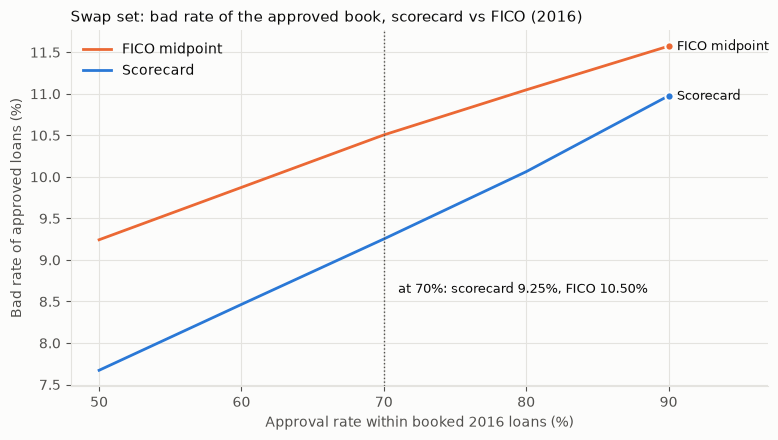

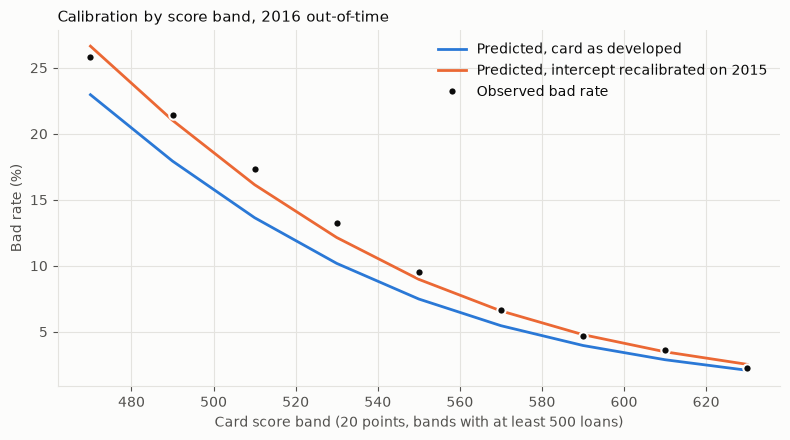

FICO midpoint, 2016: Gini 0.1805 [0.1754, 0.1855], KS 0.1354


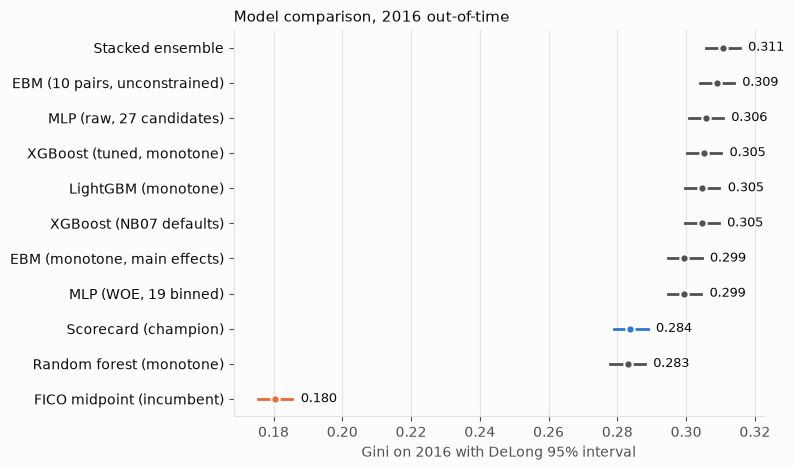

figures written to docs/figures


In [8]:
# Figures for the README (docs/figures/): swap curve, calibration by score band, model comparison with FICO
FIG_DIR = config.DOCS_DIR / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
S1, S2, S3 = "#2a78d6", "#eb6834", "#1baf7a"            # categorical slots 1-3 (validated, light surface)
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
def label_end(ax, x, y, text, color):
    ax.annotate(text, (x, y), xytext=(6, 0), textcoords="offset points", va="center", color=INK, fontsize=9)
    ax.plot([x], [y], "o", color=color, markersize=6, markeredgecolor=SURF, markeredgewidth=1.5, zorder=4)

# 1. Swap set: approved-book bad rate at each approval rate, card against FICO (same loans, same number approved)
sc = ex["swap_curve"]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(sc.approval_rate * 100, sc.bad_rate_approved_incumbent * 100, color=S2, lw=2, label="FICO midpoint")
ax.plot(sc.approval_rate * 100, sc.bad_rate_approved_challenger * 100, color=S1, lw=2, label="Scorecard")
last = sc.iloc[-1]
label_end(ax, last.approval_rate * 100, last.bad_rate_approved_incumbent * 100, "FICO midpoint", S2)
label_end(ax, last.approval_rate * 100, last.bad_rate_approved_challenger * 100, "Scorecard", S1)
r70 = sc.loc[np.isclose(sc.approval_rate, APPROVAL_RATE)].iloc[0]
ax.axvline(APPROVAL_RATE * 100, color=INK2, lw=1, ls=":")
ax.text(APPROVAL_RATE * 100 + 1, r70.bad_rate_approved_challenger * 100 - 0.6,
        f"at {APPROVAL_RATE:.0%}: scorecard {r70.bad_rate_approved_challenger:.2%}, FICO {r70.bad_rate_approved_incumbent:.2%}",
        ha="left", va="center", color=INK, fontsize=9)             # below the scorecard line, right of the marker
ax.set_xlabel("Approval rate within booked 2016 loans (%)"); ax.set_ylabel("Bad rate of approved loans (%)")
ax.set_xlim(48, 97); ax.legend(frameon=False, loc="upper left", labelcolor=INK)
ax.set_title("Swap set: bad rate of the approved book, scorecard vs FICO (2016)", loc="left", color=INK, fontsize=11)
fig.tight_layout(); fig.savefig(FIG_DIR / "swap_set_2016.png", dpi=150); plt.show()

# 2. Calibration by score band: observed vs predicted, card as developed and recalibrated on 2015
raw_b = ex["calibration_bands"]; rec_b = CARD_RECAL_BANDS
keep = raw_b["n"] >= 500
mid = raw_b.loc[keep, "band"].map(lambda b: (b.left + b.right) / 2 if hasattr(b, "left") else float(str(b).strip("[)").split(",")[0]) + 10)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(mid, raw_b.loc[keep, "predicted"] * 100, color=S1, lw=2, label="Predicted, card as developed")
ax.plot(mid, rec_b.loc[keep, "predicted"] * 100, color=S2, lw=2, label="Predicted, intercept recalibrated on 2015")
ax.plot(mid, raw_b.loc[keep, "observed"] * 100, "o", color=INK, markersize=6, markeredgecolor=SURF, markeredgewidth=1.5,
        label="Observed bad rate", zorder=5)
ax.set_xlabel("Card score band (20 points, bands with at least 500 loans)"); ax.set_ylabel("Bad rate (%)")
ax.legend(frameon=False, labelcolor=INK)
ax.set_title("Calibration by score band, 2016 out-of-time", loc="left", color=INK, fontsize=11)
fig.tight_layout(); fig.savefig(FIG_DIR / "calibration_by_band_2016.png", dpi=150); plt.show()

# 3. Model comparison on 2016: Gini with DeLong 95% intervals (models from NB07b's table, FICO computed here)
g_fico = V.delong_ci(oot["bad"].to_numpy(dtype=int), oot["fico_mid"])
print(f"FICO midpoint, 2016: Gini {g_fico['gini']:.4f} [{g_fico['gini_ci'][0]:.4f}, {g_fico['gini_ci'][1]:.4f}], "
      f"KS {V.auc_gini_ks(oot['bad'], oot['fico_mid'])['ks']:.4f}")
cmp16 = pd.read_csv(config.DOCS_DIR / "exhibits" / "challenger_comparison_oot.csv")
cmp16 = cmp16[cmp16.model != "XGBoost (tuned, recalibrated on 2015)"][["model", "gini", "gini_ci_low", "gini_ci_high"]]
cmp16 = pd.concat([cmp16, pd.DataFrame([{"model": "FICO midpoint (incumbent)", "gini": g_fico["gini"],
                                         "gini_ci_low": g_fico["gini_ci"][0], "gini_ci_high": g_fico["gini_ci"][1]}])])
cmp16 = cmp16.sort_values("gini").reset_index(drop=True)
color = lambda m: S1 if m.startswith("Scorecard") else (S2 if m.startswith("FICO") else INK2)
fig, ax = plt.subplots(figsize=(8, 4.8))
for i, r in cmp16.iterrows():
    ax.plot([r.gini_ci_low, r.gini_ci_high], [i, i], color=color(r.model), lw=2)
    ax.plot([r.gini], [i], "o", color=color(r.model), markersize=6, markeredgecolor=SURF, markeredgewidth=1.5)
    ax.annotate(f"{r.gini:.3f}", (r.gini_ci_high, i), xytext=(6, 0), textcoords="offset points", va="center", color=INK, fontsize=9)
ax.set_yticks(range(len(cmp16))); ax.set_yticklabels(cmp16.model, color=INK); ax.grid(axis="y", visible=False)
ax.set_xlabel("Gini on 2016 with DeLong 95% interval")
ax.set_title("Model comparison, 2016 out-of-time", loc="left", color=INK, fontsize=11)
fig.tight_layout(); fig.savefig(FIG_DIR / "model_comparison_2016.png", dpi=150); plt.show()
plt.rcdefaults()
print("figures written to", FIG_DIR.relative_to(config.ROOT).as_posix())

In [9]:
# Evidence — indeterminate sensitivity on 2016: bad rate and ranking with indeterminates excluded, counted as good, counted as bad
indet_s = indet.assign(gbm_score=gbm_scored(indet)["score"])
SENS = REP.indeterminate_sensitivity(oot.assign(gbm_score=oot_g["score"]), indet_s,
                                     {"card": "score", "gbm": "gbm_score", "fico": "fico_mid"})
display(SENS)
display(pd.DataFrame({"group": ["bad", "good", "indeterminate"],
                      "n": [int((oot.bad == 1).sum()), int((oot.bad == 0).sum()), len(indet)],
                      "mean_card_score": [oot.loc[oot.bad == 1, "score"].mean(), oot.loc[oot.bad == 0, "score"].mean(), indet["score"].mean()]}).round(1))
print(FICO_CAVEAT)

,treatment,n,bads,bad_rate,gini_card,ks_card,gini_gbm,ks_gbm,gini_fico,ks_fico
0,excluded (rule in force),419611,50591,0.1206,0.2838,0.2078,0.3053,0.221,0.1805,0.1354
1,counted as good,425618,50591,0.1189,0.2799,0.2050,0.3012,0.218,0.1776,0.1332
2,counted as bad,425618,56598,0.1330,0.2797,0.2046,0.3005,0.217,0.1803,0.1356


,group,n,mean_card_score
0,bad,50591,526.3
1,good,369020,541.0
2,indeterminate,6007,528.3


Lending Club used FICO in its approval, so FICO's range is truncated in this booked population (no loan below a FICO midpoint of 662 in these vintages). Its Gini here understates what FICO does on a full applicant population, and every comparison with FICO in this report measures lift over a truncated incumbent.


In [10]:
# Optional — less-discriminatory-alternative search (refits the card without each attribute; a few minutes on full data)
RUN_LDA = False
if RUN_LDA and GROUP_COL:
    Wtr = B.transform_woe(tr, specs)
    def fit_and_score(attrs):
        c = S.fit_logistic(Wtr, tr["bad"], attrs); s = S.score(oot, c, specs); return s["score"].to_numpy(), s["eta"].to_numpy()
    display(F.lda_search(fit_and_score, card.attributes, oot["bad"], oot[GROUP_COL], APPROVAL_RATE))

### Decision S — Interpretations and caveats

One paragraph per exhibit, in the dictionary below, written by you. The caveats list must include the proxy-target statement (a single Lending Club loan with the delinquency date reconstructed from the last payment, against VantageScore's observed 90+ DPD on any tradeline), the booked-population statement, and the fairness proxy.

**Your text (edit the cell below):**

**DRAFT** (Claude, 2026-11-01; for review).

**The paragraph drafts are now in the `INTERPRETATION` dict in the cell below**, each marked DRAFT, and they print into `docs/pilot_report/pilot_report.md`. Replace them with your own text.

**Caveats list:** proxy target, booked population, fairness proxy, FICO truncation, GBM recalibration, the indeterminate rule, and (new) that sections 1-4 show the card as developed while section 4a adds the card with its intercept recalibrated on 2015.

In [11]:
INTERPRETATION = {      # DRAFT paragraphs for review; replace with your own text
    'discrimination': (
        "DRAFT (Claude, 2026-11-01, for review): On the 2016 out-of-time vintage the card's Gini is 0.2838 against "
        '0.1805 for the FICO midpoint, a lift of 0.1033 (bootstrap 95% CI 0.0978 to 0.1091). FICO is truncated in this '
        'population because Lending Club used it to approve, so this is lift over a truncated incumbent, not over FICO '
        'on a full applicant population.'
    ),
    'gains': (
        "DRAFT (Claude, 2026-11-01, for review): The card's riskiest decile has a bad rate of 21.81% and holds 18.09% "
        "of all bads; FICO's riskiest decile has 16.48% and holds 13.67%. The card concentrates more of the bads in the"
        ' loans it would decline first.'
    ),
    'swap_set': (
        'DRAFT (Claude, 2026-11-01, for review): Within loans Lending Club already approved, a 70% cutoff on each score'
        " approves the same 293,728 loans in number. The 66,965 loans the card would approve instead of FICO's go bad "
        "at 11.99%; the 66,965 it would decline instead go bad at 17.48%. The approved book's bad rate falls from "
        '10.50% to 9.25%, 125 fewer bads per 10,000 approvals. The gain is 157 per 10,000 at a 50% approval rate and 60'
        ' at 90%. This is a reordering of booked loans; it says nothing about applicants Lending Club declined.'
    ),
    'calibration': (
        'DRAFT (Claude, 2026-11-01, for review): As developed, the card ranks 2016 correctly (slope 1.012, 95% CI 0.992'
        ' to 1.031) but under-predicts the level: 9.60% predicted against 12.06% observed, a calibration-in-the-large '
        'shift of 0.262 log-odds, with 8 of 11 score bands outside their interval. Recalibrating only the intercept on '
        "2015 (prior correction, +0.198 log-odds, from the 2013-2014 bad rate of 9.60% to 2015's 11.46%) brings 2016 to"
        ' 11.41% predicted, a shift of 0.064, with 3 of 11 bands outside (500-560, still under-predicted by 0.6 to 1.2 '
        'points). Like for like, the GBM recalibrated on 2015 predicts 11.17% (shift 0.090, slope 0.946). Recalibrated,'
        " the two are equally well calibrated in level (Brier 0.1033 card, 0.1029 GBM); the card's slope is closer to "
        '1.'
    ),
    'segments': (
        'DRAFT (Claude, 2026-11-01, for review): The card beats FICO in every term, file-depth and purpose segment with'
        ' enough loans: 36-month 0.2847 against 0.1834, 60-month 0.3029 against 0.1856, thin files 0.2101 against '
        '0.1128. Both scores lose discrimination through 2016 (card 0.3134 in Q1 to 0.2575 in Q4). Purposes with fewer '
        'than 1,000 loans (renewable energy 297, wedding 1) are too small to read.'
    ),
    'stability': (
        'DRAFT (Claude, 2026-11-01, for review): The PSI of 2016 scores against development is 0.0009, stable. It is '
        'statistically significant only because the sample is large (critical value 0.00009).'
    ),
    'fairness': (
        'DRAFT (Claude, 2026-11-01, for review): The proxy (Southern states against the rest) is a geographic '
        'placeholder, not a protected class: approval rates 69.15% and 70.44%, adverse impact ratio 0.9817, score SMD '
        '-0.041. This demonstrates the code path; fair-lending testing is out of scope for this data.'
    ),
}
CAVEATS = [
    "Target is a proxy: one Lending Club loan per consumer, 90+ DPD reconstructed from the last payment date, 24 months from issue; "
    "VantageScore's definition observes 90+ DPD on any tradeline over 24 months from a bureau archive.",
    "Population is booked loans only (approved by Lending Club); see NB06 for the reject-inference sensitivity.",
    f"Fair-lending groups use a documented proxy ({GROUP_COL}); no protected-class data exists in the file.",
    FICO_CAVEAT,
    "The tuned GBM in the appendix was recalibrated on 2015 (a two-parameter logistic map) before scoring 2016; "
    "its ranking is unchanged by the recalibration.",
    "Indeterminate loans (first miss inside 24 months, 90 DPD in months 25-27) are excluded from every exhibit except "
    "the indeterminate-sensitivity section.",    "Sections 1-4 show the card as developed (2013-2014 intercept). Section 4a adds the card with its intercept "
    "recalibrated on 2015 by prior correction; scores, ranking and the swap set are unchanged by it.",
]
SWAP_NOTE = ("**Population.** The 70% cutoff is applied to loans Lending Club already approved (the booked 2016 vintage). "
             "The swap set therefore shows how each score would reorder approvals within the booked population; it does "
             "not show outcomes for applicants Lending Club declined, whose outcomes are not observed (NB06).")
CAL_SECTION = (REP.md_table(CAL_CMP) + "\n\nScorecard with its intercept recalibrated on 2015, by score band:\n\n"
               + REP.md_table(CARD_RECAL_BANDS))
md_text = REP.assemble_pilot_report(ex, title="Pilot report: bureau-attribute scorecard vs FICO", lender="Lending Club (out-of-time 2016 vintage)",
                                    interpretation=INTERPRETATION, caveats=CAVEATS, path=config.DOCS_DIR / "pilot_report" / "pilot_report.md",
                                    incumbent_caveat=FICO_CAVEAT,
                                    swap_set_note=SWAP_NOTE,
                                    extra_sections={"4a. Calibration raw and recalibrated on 2015: card and GBM": CAL_SECTION,
                                                    "4b. Indeterminate sensitivity (2016)": REP.md_table(SENS)},
                                    appendix=REP.challenger_appendix("Tuned GBM, recalibrated on 2015", ex_gbm,
                                        note="XGBoost tuned on 2015 (NB07b), probabilities mapped to the 2015 level with a logistic recalibration "
                                             "fitted on 2015, then placed on the card's score scale.", incumbent_caveat=FICO_CAVEAT,
                                        swap_set_note=SWAP_NOTE))
print(md_text[:1500]); print("...\nwritten to", (config.DOCS_DIR / "pilot_report" / "pilot_report.md").relative_to(config.ROOT).as_posix())

# Pilot report: bureau-attribute scorecard vs FICO

*Lender: Lending Club (out-of-time 2016 vintage) · Validation level: out-of-time (2016 vintage) · n = 419,611 · bad rate = 12.06% · incumbent = fico_mid · approval rate for swap set = 70%*

## 1. Discrimination

| score | gini | gini_se | ks |
|---|---|---|---|
| challenger | 0.2838 | 0.0025 | 0.2078 |
| incumbent | 0.1805 | 0.0026 | 0.1354 |

Gini lift challenger - incumbent: **0.1033** (DeLong z = 35.65, p = 0; bootstrap 95% CI 0.0978 to 0.1091). Level: out-of-time (2016 vintage).

*Note on the incumbent: Lending Club used FICO in its approval, so FICO's range is truncated in this booked population (no loan below a FICO midpoint of 662 in these vintages). Its Gini here understates what FICO does on a full applicant population, and every comparison with FICO in this report measures lift over a truncated incumbent.*

DRAFT (Claude, 2026-11-01, for review): On the 2016 out-of-time vintage the card's Gini is 0.2838 against 0.1805 for th